In [25]:
from pathlib import Path
import json
import matplotlib.pyplot as plt

In [26]:
run_name = "2026-11-05_qlearningtable_4"

In [27]:
run_path = Path("../training_runs") / run_name
stats_path = run_path / "stats.json"

In [28]:
with open(stats_path) as f:
    stats = json.load(f)

In [29]:
x = [i+1 for i in range(len(stats))]
failed_y = [1 if stats[0]['end_state'] == "FAIL" else 0]

for i, ep in enumerate(stats[1:], 1):
    failed_y.append(1 if stats[i]['end_state'] == "FAIL" else 0)
    failed_y[i] += failed_y[i-1]
    
exceeded_y = [1 if stats[0]['end_state'] == "STEPS_EXCEEDED" else 0]

for i, ep in enumerate(stats[1:], 1):
    exceeded_y.append(1 if stats[i]['end_state'] == "STEPS_EXCEEDED" else 0)
    exceeded_y[i] += exceeded_y[i-1]

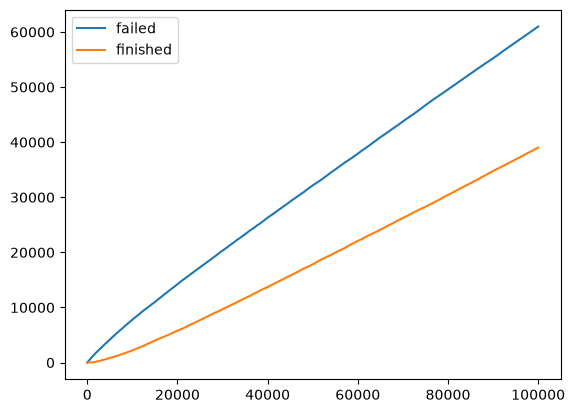

In [30]:
fig, ax = plt.subplots()

ax.plot(x, failed_y, label="failed")
ax.plot(x, exceeded_y, label="finished")

ax.legend()